# Statistical Analysis of ETH Volume and Dollar Bars

This notebook analyzes and compares the statistical properties of six ETH datasets generated using `crypto_dataset_pipeline/scripts/generate_eth_bars.sh`.

The datasets consist of three **volume bar** configurations and three **dollar (quote-notional) bar** configurations, with thresholds selected to target approximately **25, 50, and 100 bars per day**.

| Bar Type | Target Bars/Day | Threshold |
|---|---:|---:|
| Volume | 25 | 6,000 ETH |
| Volume | 50 | 3,000 ETH |
| Volume | 100 | 1,500 ETH |
| Dollar | 25 | 15,000,000 USDT |
| Dollar | 50 | 7,500,000 USDT |
| Dollar | 100 | 3,700,000 USDT |

## Objective

The goal is to evaluate and compare the statistical characteristics of these datasets, including bar frequency, return distributions, volatility, autocorrelation, and stationarity, to understand how bar type and sampling frequency affect the resulting time series.

In [2]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"

In [5]:
# Load the datasets
volume_25 = pd.read_parquet(DATASETS_DIR / "9ed666cb7603b0b1/volume.parquet")
volume_50 = pd.read_parquet(DATASETS_DIR / "f42c8eca7e1d67cf/volume.parquet")
volume_100 = pd.read_parquet(DATASETS_DIR / "486b5b7c40ebe4fd/volume.parquet")

dollar_25 = pd.read_parquet(DATASETS_DIR / "148ef03cfd675fa4/notional.parquet")
dollar_50 = pd.read_parquet(DATASETS_DIR / "7e8a02ceb035e8f9/notional.parquet")
dollar_100 = pd.read_parquet(DATASETS_DIR / "5e4cc12bf931053c/notional.parquet")

In [6]:
print("volume_25:", volume_25.shape)
print("volume_50:", volume_50.shape)
print("volume_100:", volume_100.shape)

print("dollar_25:", dollar_25.shape)
print("dollar_50:", dollar_50.shape)
print("dollar_100:", dollar_100.shape)

volume_25: (149245, 269)
volume_50: (298201, 269)
volume_100: (595326, 269)
dollar_25: (147163, 269)
dollar_50: (294042, 269)
dollar_100: (594869, 269)


In [9]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100 = map(
    set_datetime_index,
    (volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100)
)

In [11]:
print(F"Dataset columns are: {list(volume_25.columns)}")

Dataset columns are: ['bar_id', 'series_id', 'bar_type', 'bar_seq', 'segment_id', 'bar_start_us', 'bar_end_us', 'first_trade_ts_us', 'last_trade_ts_us', 'first_trade_id', 'last_trade_id', 'open', 'high', 'low', 'close', 'volume', 'notional_usdt', 'n_trades', 'n_messages', 'threshold_frozen', 'complete', 'bar_status', 'bar_available_us', 'decision_time_us', 'bar_provenance', 'bar_start', 'bar_end', 'bar_available', 'decision_time', 'ret_bars_1', 'ret_bars_5', 'ret_bars_20', 'ret_5min', 'ret_5min_ref_age_s', 'ret_1h', 'ret_1h_ref_age_s', 'ret_4h', 'ret_4h_ref_age_s', 'ret_1d', 'ret_1d_ref_age_s', 'ret_7d', 'ret_7d_ref_age_s', 'ret_30d', 'ret_30d_ref_age_s', 'rv_1h', 'rvol_1h', 'rvol_ann_1h', 'rv_1d', 'rvol_1d', 'rvol_ann_1d', 'rv_7d', 'rvol_7d', 'rvol_ann_7d', 'rv_30d', 'rvol_30d', 'rvol_ann_30d', 'rv_bars_20', 'rv_bars_100', 'bar_duration_s', 'trade_span_s', 'avg_trade_size', 'trade_intensity_per_s', 'volume_per_s', 'notional_per_s', 'aggr_buy_volume', 'aggr_sell_volume', 'aggr_signed_v

## Scope of the Analysis

This notebook focuses on analyzing and comparing the statistical properties of the six ETH volume and dollar bar datasets.

The analysis will examine bar characteristics, sampling frequency, return distributions, volatility, autocorrelation, and stationarity.

**Out of scope:** Feature validation, exploratory data analysis (EDA) of the remaining features, and comparative evaluation of their properties. These will be addressed separately.

### Bars frequencies on a weekly basis

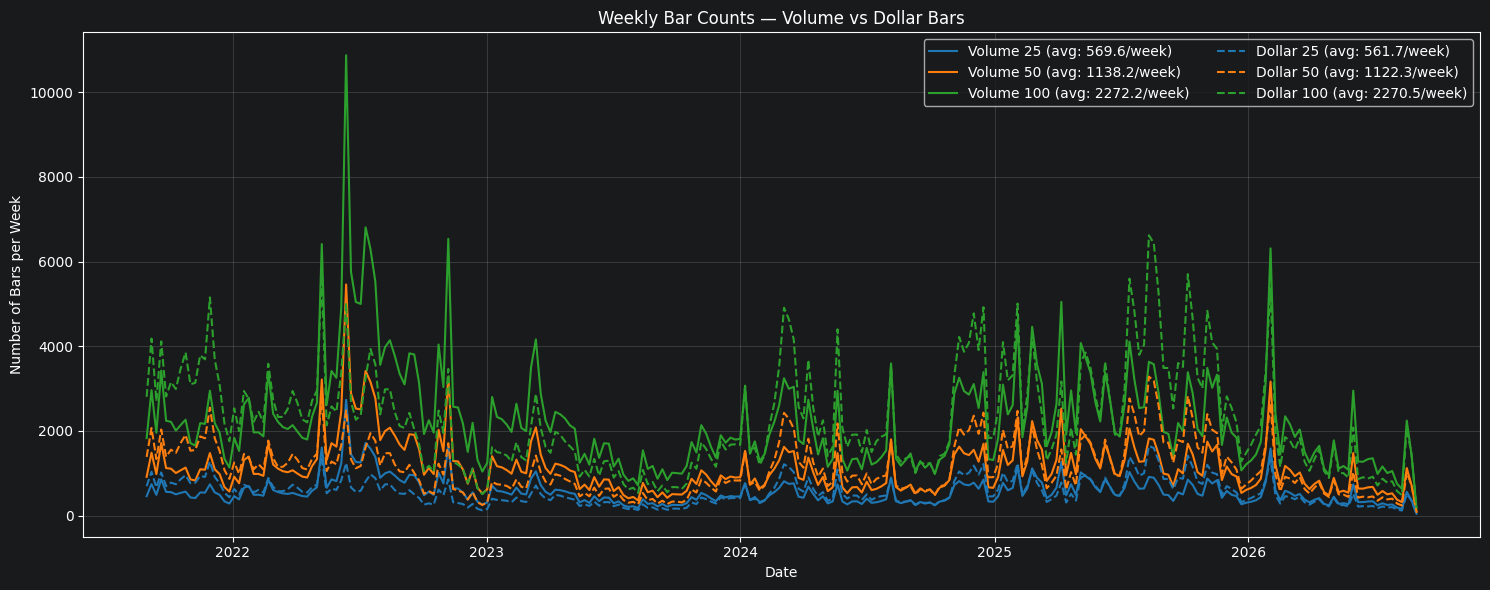

In [12]:
import matplotlib.pyplot as plt

datasets = {
    "Volume 25": volume_25,
    "Volume 50": volume_50,
    "Volume 100": volume_100,
    "Dollar 25": dollar_25,
    "Dollar 50": dollar_50,
    "Dollar 100": dollar_100,
}

colors = {25: "tab:blue", 50: "tab:orange", 100: "tab:green"}

fig, ax = plt.subplots(figsize=(15, 6))

for name, df in datasets.items():
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    weekly_counts = df.resample("W-MON", label="left", closed="left").size()

    ax.plot(
        weekly_counts.index,
        weekly_counts.values,
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.5,
        label=f"{name} (avg: {weekly_counts.mean():.1f}/week)"
    )

ax.set_title("Weekly Bar Counts — Volume vs Dollar Bars")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Bars per Week")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

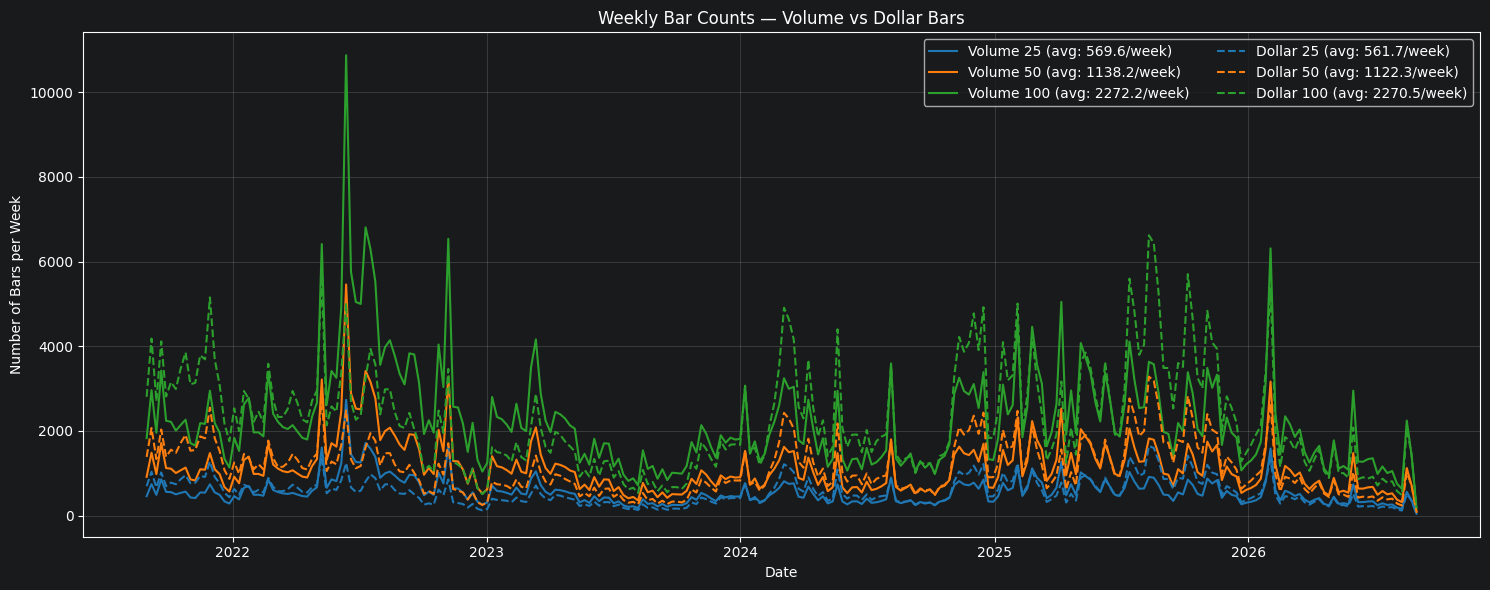

In [12]:
import matplotlib.pyplot as plt

datasets = {
    "Volume 25": volume_25,
    "Volume 50": volume_50,
    "Volume 100": volume_100,
    "Dollar 25": dollar_25,
    "Dollar 50": dollar_50,
    "Dollar 100": dollar_100,
}

colors = {25: "tab:blue", 50: "tab:orange", 100: "tab:green"}

fig, ax = plt.subplots(figsize=(15, 6))

for name, df in datasets.items():
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    weekly_counts = df.resample("W-MON", label="left", closed="left").size()

    ax.plot(
        weekly_counts.index,
        weekly_counts.values,
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.5,
        label=f"{name} (avg: {weekly_counts.mean():.1f}/week)"
    )

ax.set_title("Weekly Bar Counts — Volume vs Dollar Bars")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Bars per Week")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
def avg_bars_per_day(df):
    return df.resample("D").size().mean()

print(f"Volume 25:  {avg_bars_per_day(volume_25):.2f} bars/day")
print(f"Volume 50:  {avg_bars_per_day(volume_50):.2f} bars/day")
print(f"Volume 100: {avg_bars_per_day(volume_100):.2f} bars/day")

print(f"Dollar 25:  {avg_bars_per_day(dollar_25):.2f} bars/day")
print(f"Dollar 50:  {avg_bars_per_day(dollar_50):.2f} bars/day")
print(f"Dollar 100: {avg_bars_per_day(dollar_100):.2f} bars/day")

Volume 25:  81.73 bars/day
Volume 50:  163.31 bars/day
Volume 100: 326.03 bars/day
Dollar 25:  80.59 bars/day
Dollar 50:  161.03 bars/day
Dollar 100: 325.78 bars/day


### Compute serial correlation of returns

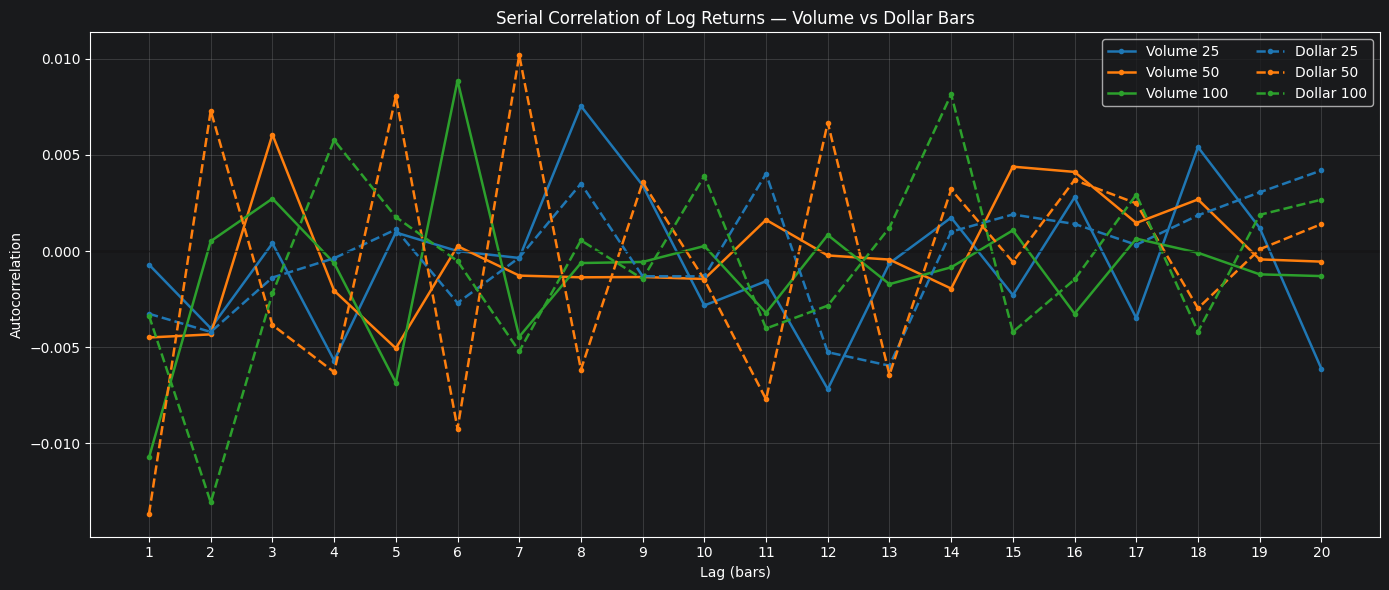

Autocorrelation at selected lags:
    Volume 25  Volume 50  Volume 100  Dollar 25  Dollar 50  Dollar 100
1     -0.0007    -0.0045     -0.0107    -0.0033    -0.0137     -0.0034
2     -0.0040    -0.0043      0.0005    -0.0042     0.0073     -0.0131
5      0.0010    -0.0051     -0.0068     0.0011     0.0080      0.0018
10    -0.0028    -0.0014      0.0003    -0.0013    -0.0015      0.0039
20    -0.0061    -0.0005     -0.0013     0.0042     0.0014      0.0027


In [15]:
import numpy as np

MAX_LAG = 20

def compute_serial_correlation(df, max_lag=20):
    df = df.sort_values("bar_seq")

    log_close = np.log(df["close"].astype(float))
    returns = log_close.groupby(df["segment_id"]).diff()

    correlations = {}

    for lag in range(1, max_lag + 1):
        lagged = returns.groupby(df["segment_id"]).shift(lag)

        valid = returns.notna() & lagged.notna()

        correlations[lag] = (
            np.corrcoef(returns[valid], lagged[valid])[0, 1]
            if valid.sum() > 2 else np.nan
        )

    return pd.Series(correlations)

acf_results = pd.DataFrame({
    name: compute_serial_correlation(df, MAX_LAG)
    for name, df in datasets.items()
})

fig, ax = plt.subplots(figsize=(14, 6))

for name in datasets:
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    ax.plot(
        acf_results.index,
        acf_results[name],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.8,
        marker="o",
        markersize=3,
        label=name
    )

ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_title("Serial Correlation of Log Returns — Volume vs Dollar Bars")
ax.set_xlabel("Lag (bars)")
ax.set_ylabel("Autocorrelation")
ax.set_xticks(range(1, MAX_LAG + 1))
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Autocorrelation at selected lags:")
print(acf_results.loc[[1, 2, 5, 10, 20]].round(4).to_string())

### Partitioned the bar series into monthly subset. This is the variance of variances of returns for every subset of every bar type.

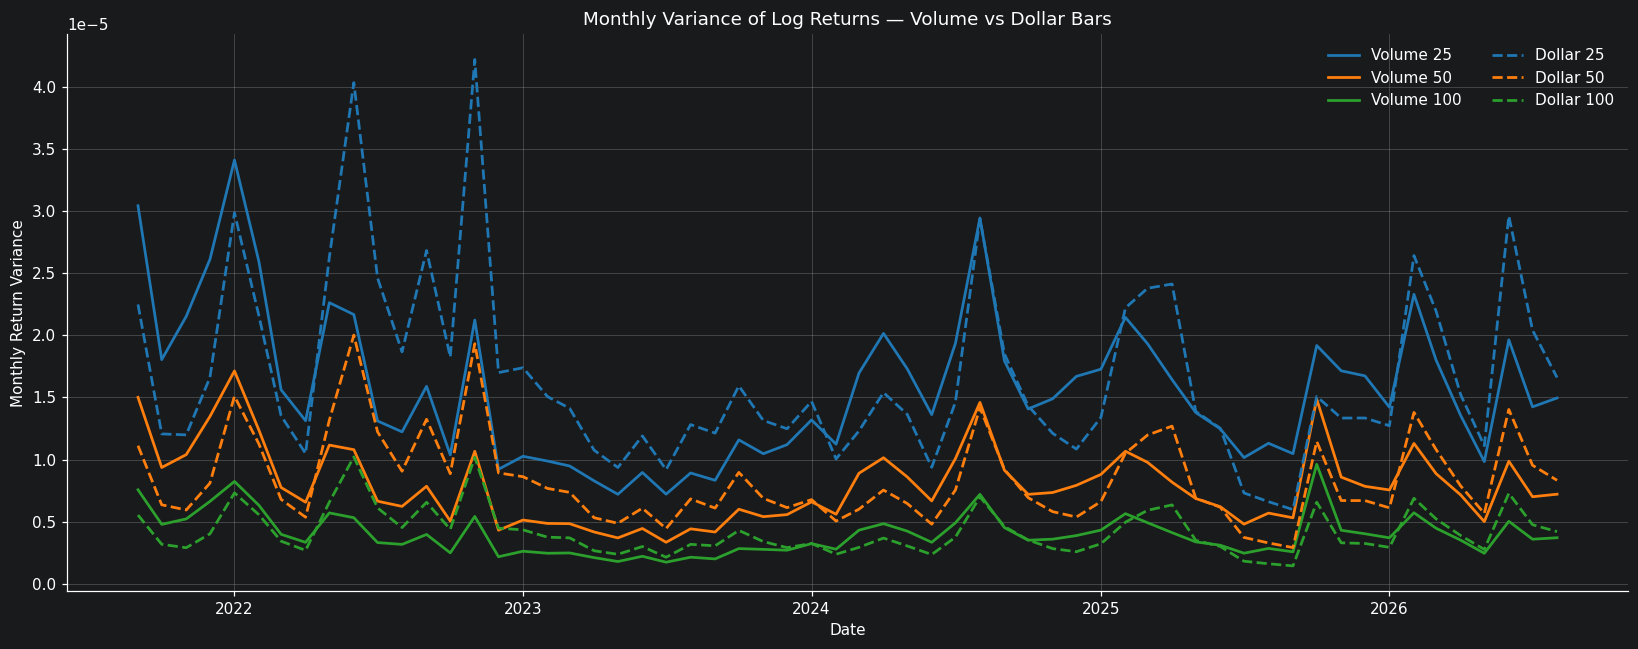

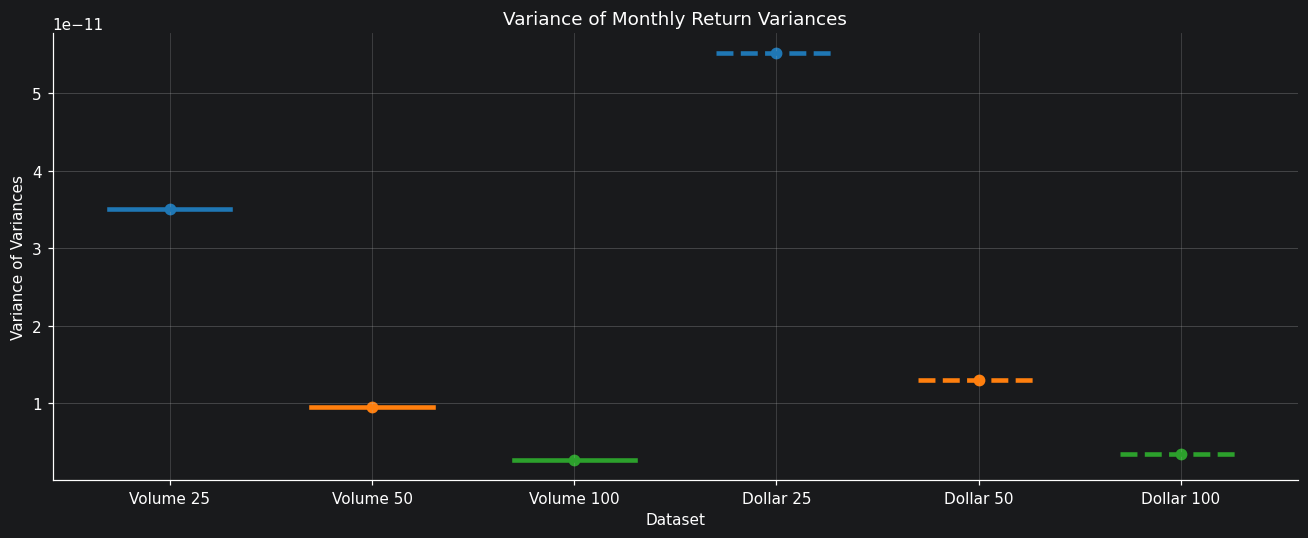


Summary Statistics:
            Monthly Variance Mean  Monthly Variance Std  Variance of Variances             CV
Volume 25          1.56918664e-05        5.92689766e-06         3.51281158e-11 3.77705080e-01
Volume 50          7.92467687e-06        3.08072249e-06         9.49085106e-12 3.88750550e-01
Volume 100         3.99633283e-06        1.64017114e-06         2.69016138e-12 4.10419055e-01
Dollar 25          1.67997137e-05        7.42565579e-06         5.51403639e-11 4.42010854e-01
Dollar 50          8.43160177e-06        3.60816230e-06         1.30188352e-11 4.27933197e-01
Dollar 100         4.19436777e-06        1.87099128e-06         3.50060836e-12 4.46072300e-01


In [32]:
import numpy as np

colors = {25: "tab:blue", 50: "tab:orange", 100: "tab:green"}


def compute_monthly_variance(df):
    df = df.sort_index(kind="stable")

    # Partition into calendar months (UTC)
    months = df.index.tz_localize(None).to_period("M")

    # Log returns computed within each month and continuous segment
    log_close = np.log(df["close"].astype(float))

    returns = log_close.groupby(
        [months, df["segment_id"].to_numpy()],
        sort=False
    ).diff()

    # Sample variance of returns for each month
    return returns.resample("MS").var(ddof=1)


# Monthly variances
monthly_variances = pd.DataFrame({
    name: compute_monthly_variance(df)
    for name, df in datasets.items()
})

# Variance of monthly variances
variance_of_variances = monthly_variances.var(ddof=1)

summary = pd.DataFrame({
    "Monthly Variance Mean": monthly_variances.mean(),
    "Monthly Variance Std": monthly_variances.std(),
    "Variance of Variances": variance_of_variances,
    "CV": monthly_variances.std() / monthly_variances.mean(),
})

# Plot 1: Monthly return variance
fig, ax = plt.subplots(figsize=(15, 6))

for name in datasets:
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"

    ax.plot(
        monthly_variances.index,
        monthly_variances[name],
        color=colors[target],
        linestyle=linestyle,
        linewidth=1.8,
        label=name
    )

ax.set_title("Monthly Variance of Log Returns — Volume vs Dollar Bars")
ax.set_xlabel("Date")
ax.set_ylabel("Monthly Return Variance")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Plot 2: Variance of monthly variances
fig, ax = plt.subplots(figsize=(12, 5))

for i, name in enumerate(datasets):
    target = int(name.split()[-1])
    linestyle = "-" if name.startswith("Volume") else "--"
    value = variance_of_variances[name]

    ax.plot(
        [i - 0.3, i + 0.3],
        [value, value],
        color=colors[target],
        linestyle=linestyle,
        linewidth=3
    )
    ax.scatter(i, value, color=colors[target], s=45)

ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets.keys())
ax.set_title("Variance of Monthly Return Variances")
ax.set_xlabel("Dataset")
ax.set_ylabel("Variance of Variances")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSummary Statistics:")
print(summary.to_string(float_format=lambda x: f"{x:.8e}"))

## Overall Findings

Overall, **volume bars exhibit more favorable statistical properties than dollar bars** across the six ETH datasets analyzed.

Volume bars consistently demonstrate:

- **Lower excess kurtosis**, indicating return distributions closer to normality.
- **Greater stability of monthly return variance**, reflected in lower coefficients of variation.
- **Lower autocorrelation of absolute returns**, suggesting less persistent volatility clustering.

Both sampling methods exhibit negligible serial correlation in raw returns and strongly reject the normality assumption.

These findings suggest that **volume bars are the more favorable sampling method for ETHUSDT in this experiment**, based on the statistical properties examined. However, further robustness testing and out-of-sample evaluation are necessary before concluding that they provide superior inputs for machine learning models.